# Laboratorio Divvy — Ejercicios Prácticos
### PY4 · Módulo 1 · Análisis de Movilidad Urbana

---

**Contexto:** Eres analista de datos en una empresa de movilidad. Tienes acceso al dataset de viajes en bicicleta de Chicago (Divvy, enero 2024) y tu misión es transformar los datos brutos en insights: ¿cuándo viaja la gente? ¿en qué zonas de la ciudad?

Este laboratorio tiene 3 fases que siguen exactamente el flujo que practicamos juntos:

| Fase | Tema | Ejercicios |
|------|------|------------|
| 🕒 **Fase 1** | Ingeniería de datos temporales | E1 → E5 |
| 🌍 **Fase 2** | Transformación geoespacial | E6 → E8 |
| 📊 **Fase 3** | Intersección y visualización | E9 → E10 |

---
> Ejecuta la celda de preparación antes de empezar.

## Preparación del entorno

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import urllib.request, zipfile, io, os, warnings
warnings.filterwarnings('ignore')

# Descarga del dataset
ARCHIVO_LOCAL = '202401-divvy-tripdata.csv'
URL = 'https://divvy-tripdata.s3.amazonaws.com/202401-divvy-tripdata.zip'

if os.path.exists(ARCHIVO_LOCAL):
    df_raw = pd.read_csv(ARCHIVO_LOCAL)
else:
    req = urllib.request.Request(URL, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as r:
        contenido = r.read()
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        with z.open(z.namelist()[0]) as f:
            df_raw = pd.read_csv(f)
    df_raw.to_csv(ARCHIVO_LOCAL, index=False)

print(f"Dataset listo: {df_raw.shape[0]:,} filas · {df_raw.shape[1]} columnas")
df_raw.head(3)

Dataset listo: 144,873 filas · 13 columnas


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,C1D650626C8C899A,electric_bike,2024-01-12 15:30:27,2024-01-12 15:37:59,Wells St & Elm St,KA1504000135,Kingsbury St & Kinzie St,KA1503000043,41.903267,-87.634737,41.889177,-87.638506,member
1,EECD38BDB25BFCB0,electric_bike,2024-01-08 15:45:46,2024-01-08 15:52:59,Wells St & Elm St,KA1504000135,Kingsbury St & Kinzie St,KA1503000043,41.902937,-87.634440,41.889177,-87.638506,member
2,F4A9CE78061F17F7,electric_bike,2024-01-27 12:27:19,2024-01-27 12:35:19,Wells St & Elm St,KA1504000135,Kingsbury St & Kinzie St,KA1503000043,41.902951,-87.634470,41.889177,-87.638506,member


---
## 🕒 Fase 1 — Ingeniería de Datos Temporales

El dataset tiene dos columnas de fechas (`started_at`, `ended_at`) que Pandas leyó como **texto**. Hay que convertirlas, extraer información útil y preparar el índice temporal.

### Ejercicio 1 — Convertir fechas

**Qué hacer:** convierte `started_at` y `ended_at` a formato `datetime` usando `pd.to_datetime()` con `errors='coerce'`.

Trabaja sobre una copia: `df = df_raw.copy()`

Al terminar, imprime los tipos de dato de las dos columnas para verificar que son `datetime64`.

In [10]:

df = df_raw.copy()

# Convertir a datetime aplicando errors='coerce'
df['started_at'] = pd.to_datetime(df['started_at'], errors='coerce')
df['ended_at'] = pd.to_datetime(df['ended_at'], errors='coerce')

# Verificar los tipos de datos
print(df[['started_at', 'ended_at']].dtypes)


started_at    datetime64[ns]
ended_at      datetime64[ns]
dtype: object


### Ejercicio 2 — Calcular duración y filtrar

**Qué hacer:**
1. Crea la columna `duracion_min`: diferencia entre `ended_at` y `started_at` en minutos.  
   *Pista:* usa `.dt.total_seconds() / 60`
2. Filtra el DataFrame para quedarte solo con viajes entre **1 y 180 minutos**.
3. Imprime cuántos viajes quedan.

In [11]:

# Calcular duración en minutos
df['duracion_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

# Filtrar viajes entre 1 y 180 minutos
df = df[(df['duracion_min'] >= 1) & (df['duracion_min'] <= 180)].copy()

print(f"Viajes restantes después del filtro: {df.shape[0]:,}")

Viajes restantes después del filtro: 139,752


### Ejercicio 3 — Extraer componentes temporales

**Qué hacer:** a partir de `started_at`, crea tres nuevas columnas usando el accessor `.dt`:
- `hora` — hora del día (0–23)
- `dia_semana` — nombre del día (ej: `'Monday'`)
- `semana` — número de semana ISO

Muestra las primeras 4 filas de esas tres columnas junto a `started_at`.

In [12]:

df['hora'] = df['started_at'].dt.hour
df['dia_semana'] = df['started_at'].dt.day_name()
df['semana'] = df['started_at'].dt.isocalendar().week

# Mostrar las primeras 4 filas de las columnas seleccionadas
df[['started_at', 'hora', 'dia_semana', 'semana']].head(4)

,started_at,hora,dia_semana,semana
0,2024-01-12 15:30:27,15,Friday,2
1,2024-01-08 15:45:46,15,Monday,2
2,2024-01-27 12:27:19,12,Saturday,4
3,2024-01-29 16:26:17,16,Monday,5


### Ejercicio 4 — DatetimeIndex y resampling diario

El *resampling* requiere que el índice sea temporal.

**Qué hacer:**
1. Establece `started_at` como índice del DataFrame y ordena cronológicamente.
2. Usa `resample('D')` para calcular, **por día**:
   - `total_viajes` — cantidad de viajes (cuenta de `ride_id`)
   - `duracion_promedio` — media de `duracion_min`
3. Muestra la tabla resultante.

In [13]:
# Tu código aquí
# Establecer índice y ordenar
df = df.set_index('started_at').sort_index()

# Resampling diario calculando la cantidad y la media de duración
df_diario = df.resample('D').agg(
    total_viajes=('ride_id', 'count'),
    duracion_promedio=('duracion_min', 'mean')
)

df_diario.head()


,total_viajes,duracion_promedio
started_at,,
2024-01-01,3520,12.236544
2024-01-02,6359,9.962358
2024-01-03,7285,10.086996
2024-01-04,7890,10.183257
2024-01-05,7244,9.943549


### Ejercicio 5 — Visualizar la tendencia diaria

**Qué hacer:** grafica el `total_viajes` por día como una línea.

El gráfico debe tener:
- Título: `'Viajes diarios — Divvy Chicago, Enero 2024'`
- Color: `'steelblue'`, marcadores de puntos (`marker='o'`)
- Cuadrícula con `alpha=0.3`

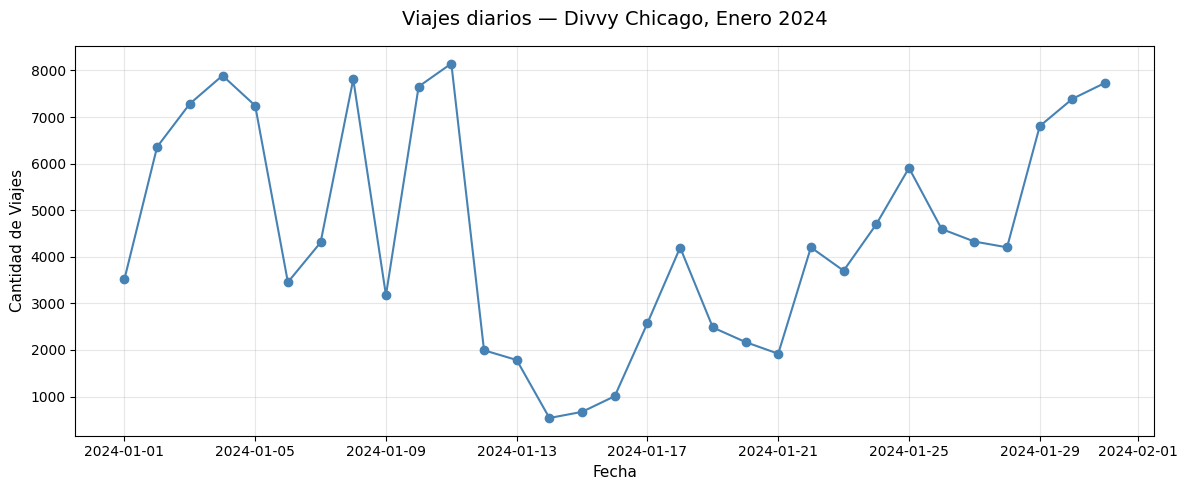

In [14]:
# Tu código aquí
plt.figure(figsize=(12, 5))
plt.plot(df_diario.index, df_diario['total_viajes'], color='steelblue', marker='o', linestyle='-')

plt.title('Viajes diarios — Divvy Chicago, Enero 2024', fontsize=14, pad=15)
plt.xlabel('Fecha', fontsize=11)
plt.ylabel('Cantidad de Viajes', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 🌍 Fase 2 — Transformación Geoespacial

El dataset tiene coordenadas (`start_lat`, `start_lng`). Vamos a convertir el DataFrame en un GeoDataFrame para poder hacer operaciones espaciales.

> Ejecuta esta celda de preparación antes de los ejercicios de esta fase.

In [15]:
# Preparación Fase 2
df_geo = df_raw.copy()
df_geo['started_at']  = pd.to_datetime(df_geo['started_at'], errors='coerce')
df_geo['ended_at']    = pd.to_datetime(df_geo['ended_at'],   errors='coerce')
df_geo['duracion_min'] = (df_geo['ended_at'] - df_geo['started_at']).dt.total_seconds() / 60
df_geo = df_geo[(df_geo['duracion_min'] > 1) & (df_geo['duracion_min'] <= 180)].copy()
df_geo = df_geo.dropna(subset=['start_lat', 'start_lng']).copy()

print(f"Registros listos: {len(df_geo):,}")

Registros listos: 139,704


### Ejercicio 6 — Crear el GeoDataFrame

**Qué hacer:**
1. Crea una lista de objetos `Point(longitud, latitud)` a partir de `start_lng` y `start_lat`.
2. Construye un `GeoDataFrame` con `gpd.GeoDataFrame(df_geo, geometry=..., crs='EPSG:4326')`.
3. Imprime el tipo del objeto, el CRS, y muestra las primeras 3 filas.

In [16]:
# Tu código aquí
# 1. Crear la lista de objetos Point
geometria = [Point(xy) for xy in zip(df_geo['start_lng'], df_geo['start_lat'])]

# 2. Construir el GeoDataFrame con CRS EPSG:4326
gdf = gpd.GeoDataFrame(df_geo, geometry=geometria, crs='EPSG:4326')

# 3. Imprimir metadatos y mostrar cabecera
print(f"Tipo de objeto: {type(gdf)}")
print(f"Sistema de Referencia (CRS): {gdf.crs}")
gdf.head(3)


Tipo de objeto: <class 'geopandas.geodataframe.GeoDataFrame'>
Sistema de Referencia (CRS): EPSG:4326


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duracion_min,geometry
0,C1D650626C8C899A,electric_bike,2024-01-12 15:30:27,2024-01-12 15:37:59,Wells St & Elm St,KA1504000135,Kingsbury St & Kinzie St,KA1503000043,41.903267,-87.634737,41.889177,-87.638506,member,7.533333,POINT (-87.63474 41.90327)
1,EECD38BDB25BFCB0,electric_bike,2024-01-08 15:45:46,2024-01-08 15:52:59,Wells St & Elm St,KA1504000135,Kingsbury St & Kinzie St,KA1503000043,41.902937,-87.634440,41.889177,-87.638506,member,7.216667,POINT (-87.63444 41.90294)
2,F4A9CE78061F17F7,electric_bike,2024-01-27 12:27:19,2024-01-27 12:35:19,Wells St & Elm St,KA1504000135,Kingsbury St & Kinzie St,KA1503000043,41.902951,-87.634470,41.889177,-87.638506,member,8.000000,POINT (-87.63447 41.90295)


Cargar los distritos de Chicago

**ejecuta la celda siguiente para cargar los distritos**


In [17]:
GEOJSON_LOCAL = 'chicago_community_areas.geojson'
URL_GEO = 'https://raw.githubusercontent.com/RandomFractals/ChicagoCrimes/master/data/chicago-community-areas.geojson'

if os.path.exists(GEOJSON_LOCAL):
    comunidades = gpd.read_file(GEOJSON_LOCAL)
else:
    comunidades = gpd.read_file(URL_GEO)
    comunidades.to_file(GEOJSON_LOCAL, driver='GeoJSON')

comunidades['community'] = comunidades['community'].str.title()

print(f"Distritos cargados: {len(comunidades)}")
print(f"CRS viajes:      {gdf.crs}")
print(f"CRS distritos:   {comunidades.crs}")
print(f"¿Mismo CRS?      {gdf.crs == comunidades.crs}")



Distritos cargados: 77
CRS viajes:      EPSG:4326
CRS distritos:   EPSG:4326
¿Mismo CRS?      True


### Ejercicio 7 — Spatial Join

Ahora vamos a cruzar los viajes con los distritos para saber **en qué zona inició cada viaje**.

**Qué hacer:**
1. Usa `gpd.sjoin(gdf, comunidades[['community', 'geometry']], how='left', predicate='within')` y guarda el resultado en `gdf_joined`.
2. Responde: ¿cuántos viajes quedaron **sin** community area asignado (iniciaron fuera de Chicago)?
3. Muestra los 5 distritos con más viajes iniciados.

In [19]:
# Tu código aquí
# 1. Realizar el join espacial
gdf_joined = gpd.sjoin(gdf, comunidades[['community', 'geometry']], how='left', predicate='within')

# 2. Contar viajes fuera de Chicago (donde la columna 'community' quedó como NaN)
viajes_fuera = gdf_joined['community'].isna().sum()
print(f"Viajes que iniciaron fuera de Chicago (sin zona asignada): {viajes_fuera:,}\n")

# 3. Mostrar los 5 distritos con más viajes
print("Top 5 distritos con más viajes iniciados:")
top_distritos = gdf_joined['community'].value_counts().head(5)
print(top_distritos)


Viajes que iniciaron fuera de Chicago (sin zona asignada): 1,706

Top 5 distritos con más viajes iniciados:
community
Near North Side    25987
Near West Side     21908
Loop               15115
Lincoln Park       12982
Lake View          12812
Name: count, dtype: int64


---
## 📊 Fase 3 — Intersección y Visualización

Combinamos las dos dimensiones: tiempo y espacio. ¿Cómo evoluciona la actividad semana a semana en cada zona?

> Ejecuta esta celda de preparación antes de los ejercicios.

In [20]:
# Preparación Fase 3
df_clean = gdf_joined.dropna(subset=['community']).copy()
df_clean['semana'] = df_clean['started_at'].dt.isocalendar().week.astype(int)
df_clean = df_clean.set_index('started_at').sort_index()

print(f"Viajes con zona asignada: {len(df_clean):,}")

Viajes con zona asignada: 137,998


### Ejercicio 8 — Tendencia semanal por zona

**Qué hacer:**
1. Usa `groupby('community')` + `resample('W')` para contar viajes por distrito y semana.
2. Aplica `.unstack(level=0).fillna(0)` para obtener una tabla donde cada columna es un distrito.
3. Identifica los **3 distritos con más viajes en total** y grafica su tendencia semanal en una sola figura (una línea por distrito).

El gráfico debe tener título, leyenda y cuadrícula.

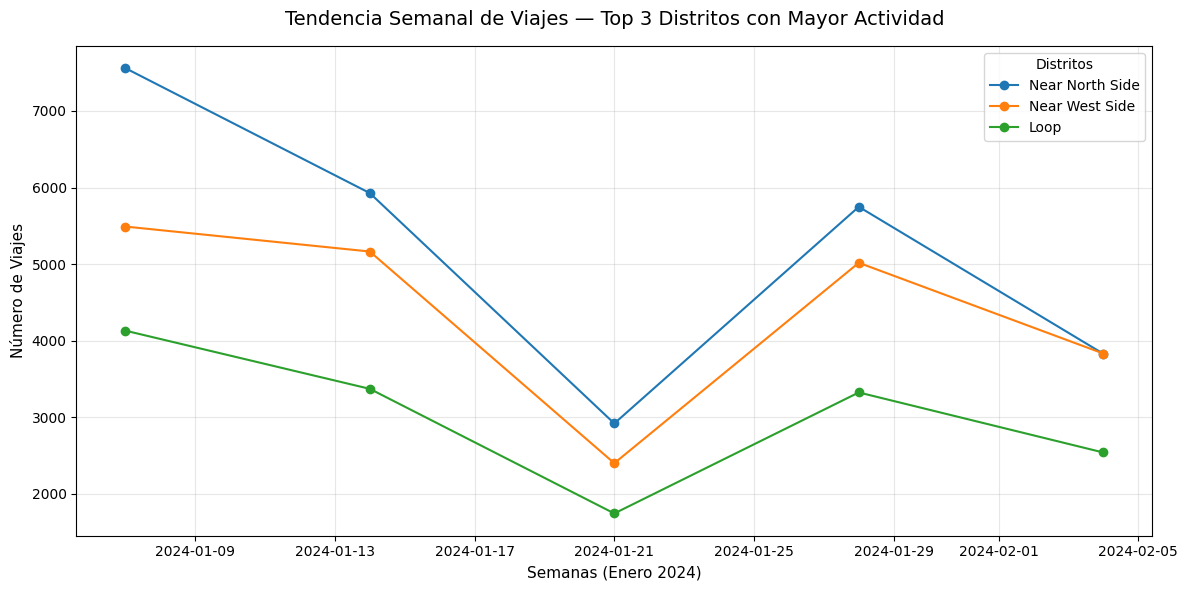

In [21]:
# Tu código aquí
# 1 y 2. Groupby + Resample semanal y desapilar (unstack) por comunidad
tabla_semanal = df_clean.groupby('community').resample('W')['ride_id'].count().unstack(level=0).fillna(0)

# 3. Identificar los 3 distritos con más viajes acumulados
top_3_zonas = df_clean['community'].value_counts().head(3).index

# Graficar la tendencia semanal del Top 3
plt.figure(figsize=(12, 6))
for zona in top_3_zonas:
    plt.plot(tabla_semanal.index, tabla_semanal[zona], marker='o', label=zona)

plt.title('Tendencia Semanal de Viajes — Top 3 Distritos con Mayor Actividad', fontsize=14, pad=15)
plt.xlabel('Semanas (Enero 2024)', fontsize=11)
plt.ylabel('Número de Viajes', fontsize=11)
plt.legend(title='Distritos')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Ejercicio 9 — Mapa de calor por zona

**Qué hacer:**
1. Calcula el total de viajes por distrito para todo el mes.
2. Une ese resultado al GeoDataFrame de polígonos (`comunidades`) usando `merge`.
3. Grafica un mapa de coropletas con `cmap='YlOrRd'` y una leyenda que diga `'Total viajes'`.

> **Pista:** `comunidades.merge(totales, on='community', how='left')` — llama `totales` al DataFrame con los totales por distrito.

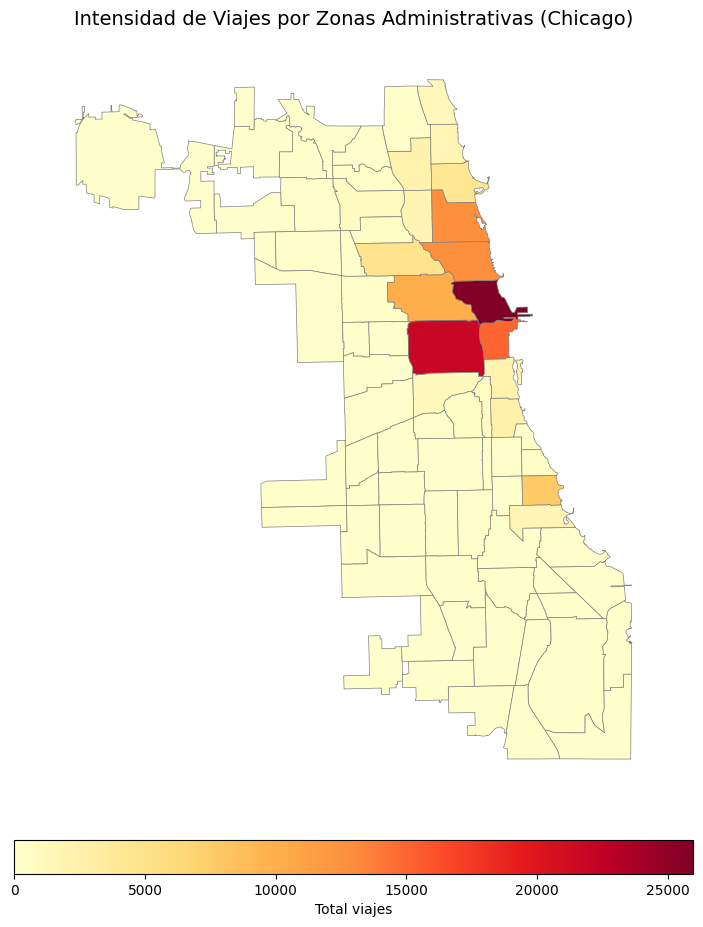

In [22]:
# Tu código aquí
# 1. Calcular el total de viajes por distrito para todo el mes
totales = df_clean['community'].value_counts().reset_index()
totales.columns = ['community', 'total_viajes']

# 2. Unir el resultado con el GeoDataFrame de polígonos original
mapa_comunidades = comunidades.merge(totales, on='community', how='left')
mapa_comunidades['total_viajes'] = mapa_comunidades['total_viajes'].fillna(0)

# 3. Graficar el mapa de coropletas
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
mapa_comunidades.plot(
    column='total_viajes',
    cmap='YlOrRd',
    linewidth=0.5,
    ax=ax,
    edgecolor='gray',
    legend=True,
    legend_kwds={'label': "Total viajes", 'orientation': "horizontal", 'shrink': 0.7, 'pad': 0.05}
)

ax.set_title('Intensidad de Viajes por Zonas Administrativas (Chicago)', fontsize=14, pad=15)
ax.axis('off') # Ocultar ejes coordenados para mejor estética del mapa
plt.tight_layout()
plt.show()

---

## ✅ ¡Completado!

En este laboratorio practicaste el flujo completo de análisis de movilidad urbana:

1. **Fase 1 — Temporal:** `pd.to_datetime()` · aritmética de `Timedelta` · accessor `.dt` · `DatetimeIndex` · `resample()`
2. **Fase 2 — Geoespacial:** `Point` (Shapely) · `GeoDataFrame` · CRS · `sjoin`
3. **Fase 3 — Integración:** `groupby + resample` · tabla pivote · mapa de coropletas

Este flujo aparece en proyectos reales de logística, movilidad, epidemiología y cualquier dominio donde los datos tienen timestamps y coordenadas.